# Supplemental Figure 3, Panel D

Lineplots showing induction of expression in response to stimulus for both IFNg and Dex. For each stimulus, early (1h) and late (6h) induced gene sets are plotted as separate lines

*Output: PanelD_lineplot.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/SuppFig4/PanelD/PanelD.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig4/PanelD

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load data

In [2]:
# load sample data (col.data), gene metadata (row.data) and table of TPMs

# TPMs
tpms <- read.delim(
  here("figures", "Figure4", "IFNy_Dex_DEGs_TPMs.tsv"),
  sep = "\t"
)

# gene-level metadata
row.data <- read.delim(
  here("figures", "Figure4", "IFNy_Dex_DEGs_rowdata.tsv"),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here("figures", "Figure4", "IFNy_Dex_DEGs_coldata.tsv"),
  sep = "\t"
)

colnames(tpms) <- paste0(col.data$group, "_", col.data$replicate)

# read in differential expression analysis results

# stimulus vs vehicle
ifn_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "IFNy_1h_DEGs.tsv"),
  sep = "\t"
)

ifn_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "IFNy_6h_DEGs.tsv"),
  sep = "\t"
)

dex_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "Dex_1h_DEGs.tsv"),
  sep = "\t"
)

dex_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "Dex_6h_DEGs.tsv"),
  sep = "\t"
)
#define 1h-induced and 6h-induced gene sets
ifn_up_1h <- (ifn_1h$change == "up" & ifn_6h$change != "up") | (ifn_1h$change == "up" & ifn_6h$change == "up")
sum(ifn_up_1h)
ifn_up_6h <-  (ifn_1h$change != "up" & ifn_6h$change == "up")
sum(ifn_up_6h)

dex_up_1h <- (dex_1h$change == "up" & dex_6h$change != "up") | (dex_1h$change == "up" & dex_6h$change == "up") 
sum(dex_up_1h)
dex_up_6h <- (dex_1h$change != "up" & dex_6h$change == "up")
sum(dex_up_6h)

[1] 41

[1] 114

[1] 31

[1] 328

# Scale and vehicle-normalize TPMs

In [3]:
#IFNy
#filter for only columns containing vehicle or IFNy treatment
col.data_ifn <- col.data[grep("IFN|Veh",col.data$group),]
tpm_ifn <- tpm[,grep("IFN|Veh",col.data$group)] %>% `colnames<-`(col.data_ifn$group)

#average over replicates (Vehicle or IFNy-alone conditions only)
tpm_ifn_mean <- data.frame(
    IFN_1=rowMeans(tpm_ifn[,3:4]),
    Veh_1=rowMeans(tpm_ifn[,5:6]),
    IFN_6=rowMeans(tpm_ifn[,9:10]),
    Veh_6=rowMeans(tpm_ifn[,11:12])
)
head(tpm_ifn_mean)

#filer to only include IFNy-inducible genes
ifn_inducible <- rbind(tpm_ifn_mean[ifn_up_1h,],tpm_ifn_mean[ifn_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_ifn_inducible <- rbind(row.data[ifn_up_1h,],row.data[ifn_up_6h,]) %>% mutate(category=c(rep("up_1h", 41), rep("up_6h", 114)))

#average over vehicle, log-normalize, and scale expression (Z-score)
ifn_inducible_scale <- 
    ifn_inducible %>% 
        mutate(Veh=(Veh_1 + Veh_6)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1, Veh_6)) %>% 
        +1 %>% log2() %>% #log-normalize
        apply(MARGIN=1,FUN=scale) %>% t() %>% #scale by row
        data.frame() %>% 
        `colnames<-`(c("IFN_1", "IFN_6", "Veh"))
head(ifn_inducible_scale)


#Dex
#filter for only columns containing vehicle or Dex treatment
col.data_dex <- col.data[grep("Dex|Veh",col.data$group),]
tpm_dex<- tpm[,grep("Dex|Veh",col.data$group)] %>% `colnames<-`(col.data_dex$group)

#average over replicates (Vehicle or Dex-alone conditions only)
tpm_dex_mean <- data.frame(
    Dex_1=rowMeans(tpm_dex[,3:4]),
    Veh_1=rowMeans(tpm_dex[,5:6]),
    Dex_6=rowMeans(tpm_dex[,9:10]),
    Veh_6=rowMeans(tpm_dex[,11:12])
)
head(tpm_dex_mean)

#filer to only include Dex-inducible genes
dex_inducible <- rbind(tpm_dex_mean[dex_up_1h,],tpm_dex_mean[dex_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_dex_inducible <- rbind(row.data[dex_up_1h,],row.data[dex_up_6h,]) %>% mutate(category=c(rep("up_1h", 31), rep("up_6h", 328)))

#average over vehicle, log-normalize, and scale expression (Z-score)
dex_inducible_scale <- 
    dex_inducible %>% 
        mutate(Veh=(Veh_1 + Veh_6)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1, Veh_6)) %>% 
        +1 %>% log2() %>% #log-normalize
        apply(MARGIN=1,FUN=scale) %>% t() %>% #scale by row
        data.frame() %>% 
        `colnames<-`(c("Dex_1", "Dex_6", "Veh"))
head(dex_inducible_scale)

,IFN_1,Veh_1,IFN_6,Veh_6
,<dbl>,<dbl>,<dbl>,<dbl>
1,58.170,58.970,60.150,60.925
2,14.380,13.995,15.035,14.050
3,424.660,389.845,596.630,429.185
4,24.475,22.685,20.315,23.700
5,10.720,10.790,13.080,10.125
6,11.085,10.220,8.050,11.085


,IFN_1,IFN_6,Veh
,<dbl>,<dbl>,<dbl>
483,1.11791495,-0.3085585,-0.8093564
539,-0.03369545,1.0164219,-0.9827264
542,-0.20249030,1.0857492,-0.8832589
673,0.73330160,0.4058138,-1.1391154
715,0.36960341,0.7625868,-1.1321902
733,0.49646655,0.6546182,-1.1510847


,Dex_1,Veh_1,Dex_6,Veh_6
,<dbl>,<dbl>,<dbl>,<dbl>
1,56.845,58.970,60.440,60.925
2,15.520,13.995,13.465,14.050
3,368.695,389.845,255.500,429.185
4,23.460,22.685,17.130,23.700
5,10.170,10.790,11.140,10.125
6,10.645,10.220,12.480,11.085


,Dex_1,Dex_6,Veh
,<dbl>,<dbl>,<dbl>
698,0.6085626,0.5455650,-1.154128
715,0.7545019,0.3797465,-1.134248
1007,0.3590743,0.7708834,-1.129958
1386,0.4887867,0.6615955,-1.150382
1447,0.2298718,0.8650484,-1.094920
1702,0.4355552,0.7083534,-1.143909


# Generate plots

In [4]:
#generate lineplot - median with IQR
lineplot_ifn_median <- ifn_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - ifn_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_ifn_inducible$category, Veh_BRM=Veh) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(time=as.numeric(ifelse(grepl("Veh", name), 0, gsub("^.*_","",name)))) %>% 
    group_by(cat,time) %>% 
            summarize(median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75)) %>% #summarize data
    ggplot() +
        geom_ribbon(aes(x=time,ymin=pctile_25, ymax=pctile_75, group=cat, fill=cat), alpha=.1) + 
        geom_line(aes(x=time,y=median, group=cat, color=cat), linewidth=1) +
        geom_point(aes(x=time,y=median, group=cat, color=cat), size=2) +
        ylab("Normalized expression") +
        xlab("IFNy treatment (h)") +
        scale_color_manual(values=c("#1c9e77", "#127555")) +
        scale_fill_manual(values=c("#1c9e77", "#127555"))  +
        ggtitle(paste("IFNy-inducible genes, n =", nrow(ifn_inducible_scale))) +
        scale_y_continuous(breaks=c(0,1,2)) +
        scale_x_continuous(breaks=c(0,1,6))

#generate lineplot - median with IQR
lineplot_dex_median <- dex_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - dex_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_dex_inducible$category, Veh_BRM=Veh) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(time=as.numeric(ifelse(grepl("Veh", name), 0, gsub("^.*_","",name)))) %>% 
    group_by(cat,time) %>% 
            summarize(median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75)) %>% #summarize data
    ggplot() +
        geom_ribbon(aes(x=time,ymin=pctile_25, ymax=pctile_75, group=cat, fill=cat), alpha=.1) + 
        geom_line(aes(x=time,y=median, group=cat, color=cat), linewidth=1) +
        geom_point(aes(x=time,y=median, group=cat, color=cat), size=2) +
        ylab("Normalized expression") +
        xlab("Dex treatment (h)") +
        scale_color_manual(values=c("#5791c9", "#4878a6")) +
        scale_fill_manual(values=c("#5791c9", "#4878a6"))  +
        ggtitle(paste("Dex-inducible genes, n =", nrow(dex_inducible_scale))) +
        scale_y_continuous(breaks=c(0,1,2)) +
        scale_x_continuous(breaks=c(0,1,6))

`summarise()` has grouped output by 'cat'. You can override using the `.groups`
argument.
`summarise()` has grouped output by 'cat'. You can override using the `.groups`
argument.


# Assemble figure panel

Saving 5 x 7 in image


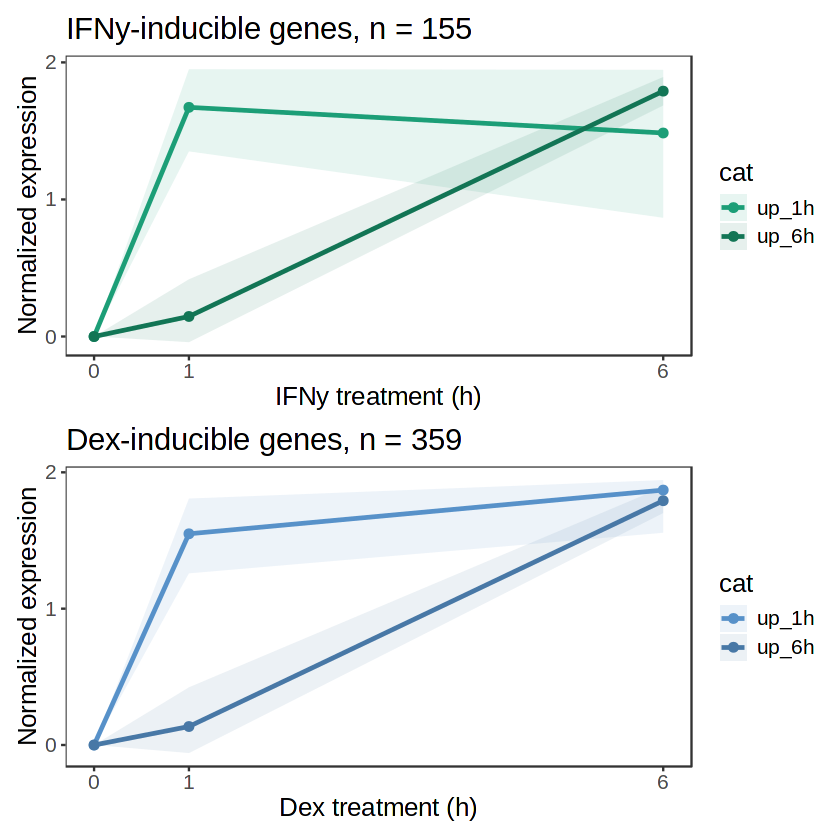

In [5]:

lineplot_ifn_median / lineplot_dex_median
ggsave("PanelD_lineplot.pdf", width=5)